# Projected BiHalofit Tutorial

`make_projected_bihalofit` computes the weak-lensing convergence bispectrum
$B_\kappa(\ell_1,\ell_2,\ell_3)$ from the 3D BiHalofit bispectrum with the Limber approximation. The
pattern is the same as for the 3D bispectrum:

```python
bk      = make_projected_bihalofit(ell1, ell2, ell3, dndz, tracers)   # once: fix triangles, n(z), tracers
B_kappa = bk(cosmo)                                                   # then: evaluate at any Cosmology
```

`B_kappa` has shape `(N_cosmo, N_ltri)`; $\ell$ and $B_\kappa$ are dimensionless. Every step, from
$\chi(z)$ to the linear $P(k)$, is pure JAX, so `bk` can be `jit`ted, `vmap`ped and differentiated with
respect to all eight cosmological parameters. Source: `src/projected_bispectrum.py`.

**Parameter convention** (as in the BiHalofit kernel and baccoemu): all densities are dimensionless.
`omega_cold` $=\Omega_{\rm cdm}+\Omega_b$ already includes the baryons, and `omega_baryon` $=\Omega_b$.
The total matter density adds the neutrinos, $\Omega_m=$ `omega_cold` $+\,\Omega_\nu$ with
$\Omega_\nu=\Sigma m_\nu/(93.14\,{\rm eV}\,h^2)$. These are not physical densities $\omega=\Omega h^2$,
so do not divide by $h^2$.

## The Limber formula

$$B_\kappa(\ell_1,\ell_2,\ell_3)
= \int_0^{\chi_H} \frac{[q(\chi)]^3}{\chi^4}\,
  B_\delta\!\left(\frac{\ell_1}{\chi},\frac{\ell_2}{\chi},\frac{\ell_3}{\chi};z(\chi)\right) d\chi,$$

with $q(\chi) = \frac{3}{2}\Omega_m\frac{H_0^2}{c^2}\frac{\chi}{a(\chi)}\,g(\chi)$ and
$g(\chi) = \int_\chi^{\chi_H} n_z(z')\frac{\chi(z')-\chi}{\chi(z')}\,dz'$.

The integral is a fixed Gauss–Legendre sum over `N_chi` nodes in $\chi$ (default 160), shared by all
cosmologies, so the BiHalofit kernel is compiled once. Galaxy-clustering samples narrower than the node spacing
need more nodes (about 8000 Mpc/h divided by the radial width of $n(z)$; the library warns). $\chi(z)$, $a(\chi)$ and $g(\chi)$ are recomputed
for each cosmology in JAX.

## 0. Setup

Imports `bihalofit_jax`, which must be installed.

In [1]:
import sys, os

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

import bihalofit_jax    # pip install bihalofit-jax, or pip install -e . from a checkout

import numpy as np
import jax
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from bihalofit_jax import Cosmology, make_projected_bihalofit, smail_nz

# Figure style: boxed axes with inward ticks on all four sides, no grid, no titles, 2-point lines,
# a colour-blind-safe cycle, one fixed colour per backend, and a single-hue blue ramp for ordered quantities.
plt.rcParams.update({
    'figure.figsize': (7.5, 4.8), 'figure.dpi': 110, 'figure.constrained_layout.use': True,
    'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 14, 'axes.labelsize': 16,
    'axes.linewidth': 0.8, 'axes.grid': False, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'xtick.major.size': 5, 'ytick.major.size': 5, 'xtick.minor.size': 2.5, 'ytick.minor.size': 2.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'legend.frameon': False, 'legend.fontsize': 13,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100']),
})
BLUES  = LinearSegmentedColormap.from_list('blues', ['#86b6ef', '#184f95'])
COLOUR = {'baccoemu': '#2a78d6', 'syren': '#eb6834', 'eh': '#1baf7a', 'eh_99': '#eda100'}
print('bihalofit_jax:', bihalofit_jax.__file__)
print('JAX device:', jax.devices())

bihalofit_jax: /tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/bihalofit_jax/__init__.py
JAX device: [CpuDevice(id=0)]


## 1. Source redshift distribution

`smail_nz` returns a Smail-type $n(z)$ normalised to 1, here with LSST-like parameters. A distribution
is passed as a `(z, n(z))` tuple, with `z[0] == 0`.

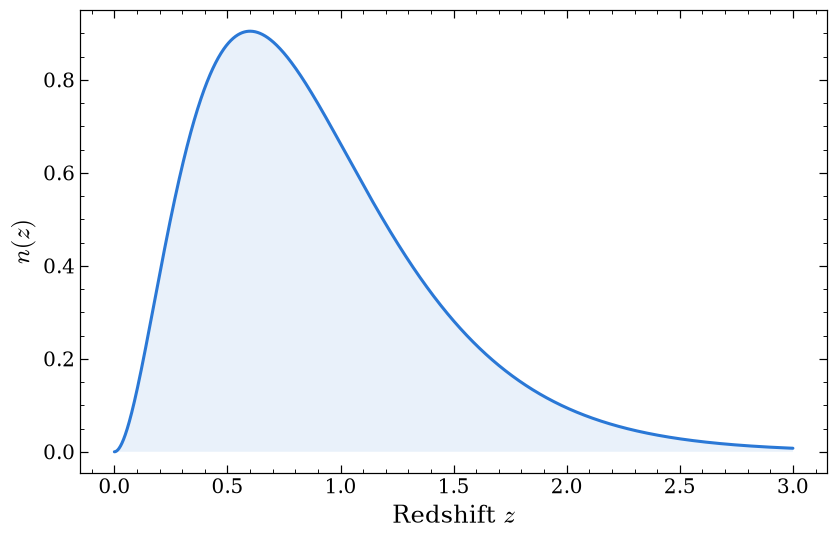

In [2]:
z_arr  = np.linspace(0.0, 3.0, 2000)
nz_arr = smail_nz(z_arr, z0=0.3, alpha=2.0, beta=1.0)
n_z    = (z_arr, nz_arr)

fig, ax = plt.subplots()
ax.plot(z_arr, nz_arr)
ax.fill_between(z_arr, nz_arr, alpha=0.1)
ax.set_xlabel('Redshift $z$'); ax.set_ylabel(r'$n(z)$')
plt.show()

## 2. Angular triangles

`ell1, ell2, ell3` are arrays of shape `(N_ltri,)`: triangle $i$ is $(\ell_1[i], \ell_2[i], \ell_3[i])$.
Here, every closed triangle on a log-spaced grid of integer multipoles.

In [3]:
ells = np.unique(np.round(np.geomspace(2, 1500, 50)).astype(int))
ell1, ell2, ell3 = np.array([(a, b, c) for i, a in enumerate(ells) for j, b in enumerate(ells[i:], i)
                             for c in ells[j:] if c <= a + b]).T          # ell1 <= ell2 <= ell3 <= ell1 + ell2
eq = (ell1 == ell2) & (ell2 == ell3)                                     # the equilateral triangles
print(f'{len(ell1)} triangles, {eq.sum()} equilateral')

2411 triangles, 46 equilateral


## 3. Convergence bispectrum for one cosmology

`tracers` names the projection kernel of each of the three legs. `'lensing'` on all three is classic
cosmic shear (section 7 mixes them), and `dndz` holds one $n(z)$ per leg. The default linear-$P(k)$
backend is `'syren'`, pure JAX and quick to compile; section 4 compares the others.

(1, 2411)


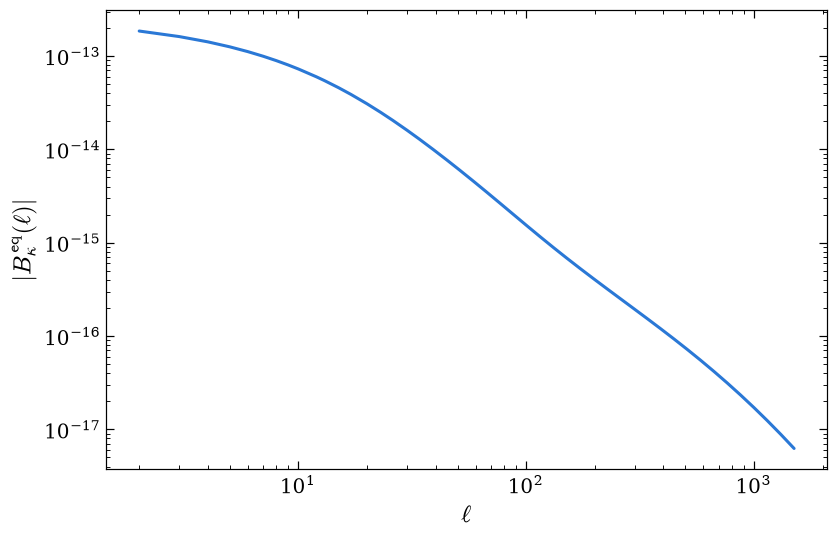

In [4]:
cosmo = Cosmology(omega_cold=np.array([0.3089]), omega_baryon=np.array([0.0486]),
                  sigma8_cold=np.array([0.8159]), ns=np.array([0.9667]), hubble=np.array([0.6774]))
# neutrino_mass, w0 and wa keep their defaults (0, -1, 0)

bk      = make_projected_bihalofit(ell1, ell2, ell3, (n_z, n_z, n_z), ('lensing',) * 3, pk_source='syren')
B_kappa = bk(cosmo)                                        # (N_cosmo, N_ltri) = (1, 2411)
print(B_kappa.shape)

fig, ax = plt.subplots()
ax.loglog(ell1[eq], np.abs(B_kappa[0, eq]))
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$|B_\kappa^{\rm eq}(\ell)|$')
plt.show()

## 4. Linear $P(k)$ backends

`pk_source` selects the linear power spectrum: `'syren'` (default, an analytic fit), `'baccoemu'` (a
neural-network emulator that needs TensorFlow) or `'eh'` (Eisenstein & Hu 1998, no wiggles); `'syren'`
and `'eh'` are pure JAX. All three respond to all eight parameters, except that `eh` responds only weakly to
`neutrino_mass` and acts on `w0` and `wa` only through the growth factor.

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


/tmp/ipykernel_3793070/590146081.py:2: RuntimeWarning: chi_max=5800 Mpc/h reaches a(chi) ~ 0.084 for high-Omega_m cosmologies, below the baccoemu emulator's trained expfactor bound 0.1; the emulator would extrapolate silently on the deepest chi-nodes. Reduce chi_max or use pk_source='syren'/'eh'.
  B_backends = {b: make_projected_bihalofit(ell1, ell2, ell3, (n_z, n_z, n_z), ('lensing','lensing','lensing'),


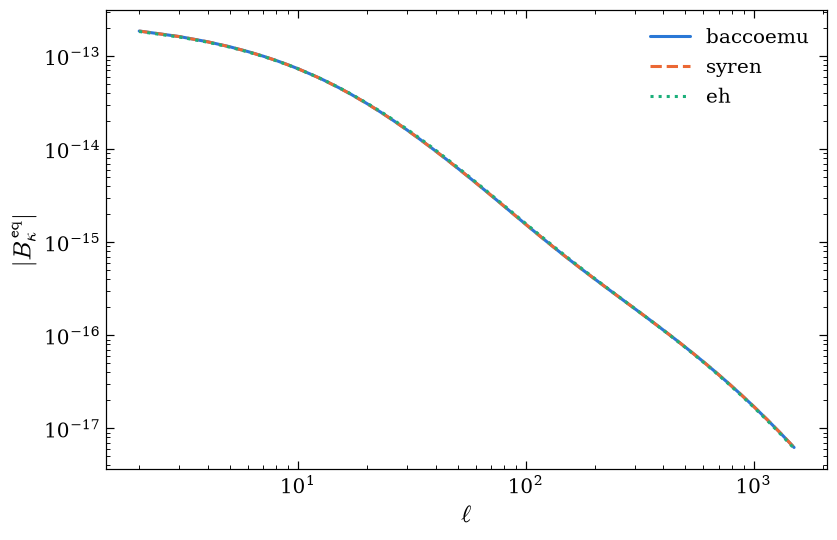

In [5]:
backends = ['baccoemu', 'syren', 'eh']
B_backends = {b: make_projected_bihalofit(ell1, ell2, ell3, (n_z, n_z, n_z), ('lensing','lensing','lensing'),
                                          pk_source=b)(cosmo) for b in backends}

fig, ax = plt.subplots()
for b, ls in zip(backends, ('-', '--', ':')):
    ax.loglog(ell1[eq], np.abs(B_backends[b][0, eq]), ls=ls, color=COLOUR[b], label=b)
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$|B_\kappa^{\rm eq}|$'); ax.legend()
plt.show()

## 5. Multiple cosmologies

Give the `Cosmology` fields arrays of length `N_cosmo`; `bk` evaluates all of them in one call and the
output is `(N_cosmo, N_ltri)`. Here, 20 values of $\sigma_8$.

(20, 2411)


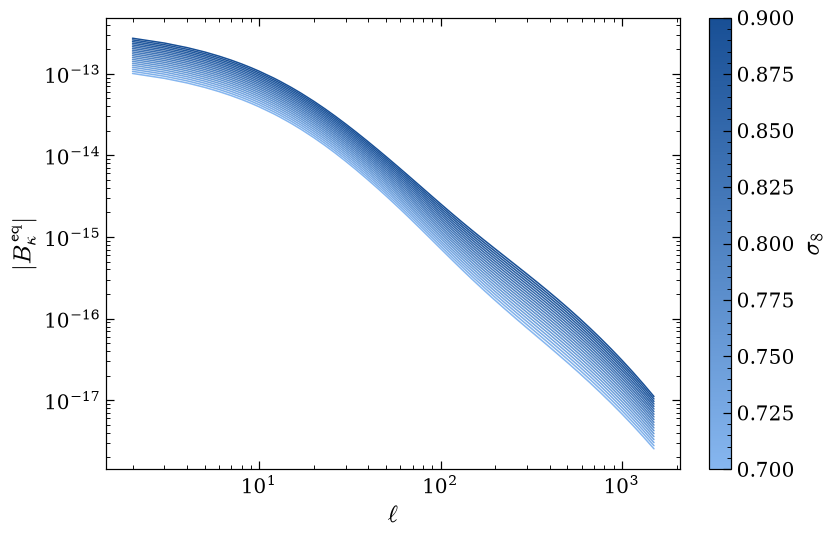

In [6]:
N = 20
sigma8 = np.linspace(0.7, 0.9, N)
ones   = np.ones(N)
cosmos = Cosmology(omega_cold=0.3089 * ones, omega_baryon=0.0486 * ones, sigma8_cold=sigma8,
                   ns=0.9667 * ones, hubble=0.6774 * ones)

B_multi = np.asarray(bk(cosmos))                           # (N_cosmo, N_ltri) = (20, 2411)
print(B_multi.shape)

fig, ax = plt.subplots()
for i in range(N):
    ax.loglog(ell1[eq], np.abs(B_multi[i, eq]), color=BLUES(i / (N - 1)), lw=1)
plt.colorbar(plt.cm.ScalarMappable(cmap=BLUES, norm=plt.Normalize(0.7, 0.9)), ax=ax, label=r'$\sigma_8$')
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$|B_\kappa^{\rm eq}|$')
plt.show()

## 6. Derivatives with JAX

`bk` is a pure JAX function, so JAX's transformations apply to it directly. `jax.jacfwd(bk)(cosmo)`
returns the derivative of every output with respect to every parameter. Because `Cosmology` is a
pytree, the result is another `Cosmology` whose fields hold the derivatives: `jac.omega_cold` is
$\partial B_\kappa/\partial\Omega_{\rm cold}$. Each has shape `(N_cosmo, N_ltri, N_cosmo)`: the axes of
`B_kappa`, then the shape of the parameter.

Below are the responses $d\ln B_\kappa/d\ln\theta=(\partial B_\kappa/\partial\theta)\,\theta/B_\kappa$
to $\Omega_{\rm cold}$ and $\sigma_8$: the percentage change in $B_\kappa$ for a 1% change in the
parameter, with the others held fixed.

(1, 2411, 1)


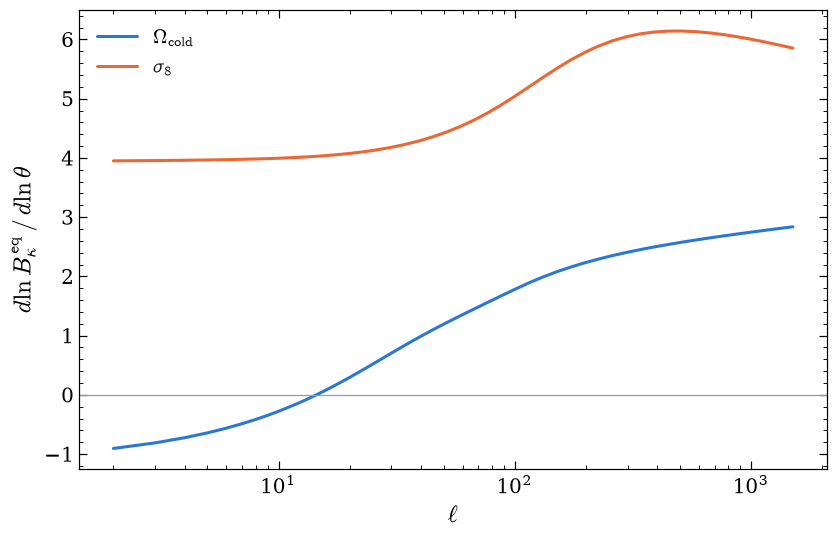

In [7]:
jac = jax.jacfwd(bk)(cosmo)                                # a Cosmology whose fields are derivatives
print(jac.omega_cold.shape)                                # (N_cosmo, N_ltri, N_cosmo) = (1, 2411, 1)

dlnB_dlnOmega = jac.omega_cold[0, :, 0] / B_kappa[0] * cosmo.omega_cold[0]
dlnB_dlnsigma8 = jac.sigma8_cold[0, :, 0] / B_kappa[0] * cosmo.sigma8_cold[0]

fig, ax = plt.subplots()
ax.semilogx(ell1[eq], dlnB_dlnOmega[eq], label=r'$\Omega_{\rm cold}$')
ax.semilogx(ell1[eq], dlnB_dlnsigma8[eq], label=r'$\sigma_8$')
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$d\ln B_\kappa^{\rm eq}\,/\,d\ln\theta$'); ax.legend()
plt.show()

## 7. Mixing tracers

Each leg can use its own tracer, and `dndz` and `bias` are then given per leg:

- `'lensing'`: weak-lensing efficiency kernel from a source $n(z)$, as above.
- `'counts'`: galaxy clustering kernel from a lens $n(z)$ and a linear bias.
- `'cmb_lensing'`: single-source-plane lensing kernel at `z_source`, with no $n(z)$ (pass `None`).
- `'ia'`: intrinsic-alignment kernel from a source $n(z)$, with no bias (section 8).

Mixing them gives galaxy-galaxy lensing, `('counts', 'lensing', 'lensing')`, or a CMB-lensing cross
term, with the same compilation and the same gradients as before.

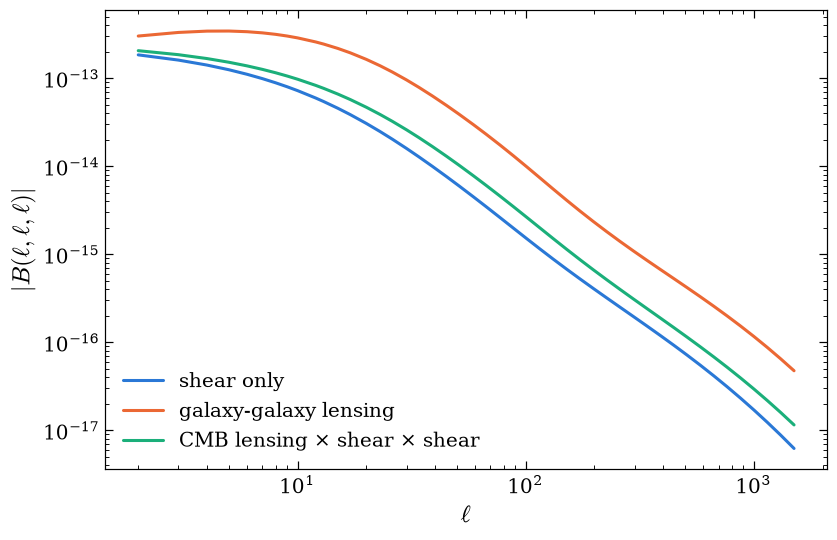

In [8]:
z_lens   = np.linspace(0.0, 3.0, 2000)
lens_n_z = (z_lens, smail_nz(z_lens, z0=0.4, alpha=2.0, beta=1.0))      # a lower-redshift lens sample

bk_ggl = make_projected_bihalofit(ell1, ell2, ell3, (lens_n_z, n_z, n_z), ('counts', 'lensing', 'lensing'),
                                  bias=(1.7, None, None), pk_source='syren')
# The CMB kernel reaches far beyond the default chi_max (z~3), but the two source legs have no support
# there, so the product has none either and nothing is lost (a larger chi_max changes B by <0.002%).
bk_cmb = make_projected_bihalofit(ell1, ell2, ell3, (None, n_z, n_z), ('cmb_lensing', 'lensing', 'lensing'),
                                  z_source=(1089.0, 1089.0, 1089.0), pk_source='syren')

fig, ax = plt.subplots()
ax.loglog(ell1[eq], np.abs(B_kappa[0, eq]), label='shear only')
ax.loglog(ell1[eq], np.abs(bk_ggl(cosmo)[0, eq]), label='galaxy-galaxy lensing')
ax.loglog(ell1[eq], np.abs(bk_cmb(cosmo)[0, eq]), label='CMB lensing × shear × shear')
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$|B(\ell,\ell,\ell)|$'); ax.legend()
plt.show()

## 8. Intrinsic alignments

Physically aligned source galaxies add an intrinsic shear $\gamma^I$ to the lensing signal. In the
nonlinear alignment (NLA) model it is proportional to the matter field, $\delta_I=f_{\rm IA}(z)\,\delta$, with

$$f_{\rm IA}(z)=-A_{\rm IA}\,C_1\rho_{\rm crit}\,\frac{\Omega_m}{D(z)}\left(\frac{1+z}{1+z_{\rm pivot}}\right)^{\eta},
\qquad C_1\rho_{\rm crit}=0.0134,$$

where $D(0)=1$ is the linear growth factor. The `'ia'` tracer is the kernel $f_{\rm IA}(z)\,n(z)\,H(z)/c$,
and the observed bispectrum is the sum of the terms with one, two or three legs replaced by it:

$$B_{\rm obs}=B_{GGG}+3B_{GGI}+3B_{GII}+B_{III}.$$

Each term is its own `make_projected_bihalofit` call with the matching `tracers`, and you add up the terms
you want. The alignment parameters are an `IA(A_IA, eta)` passed at call time, so like the cosmology they
can be arrays over `N_cosmo` and are differentiable. The pivot `z_pivot` (default 0.62) is fixed at build time.

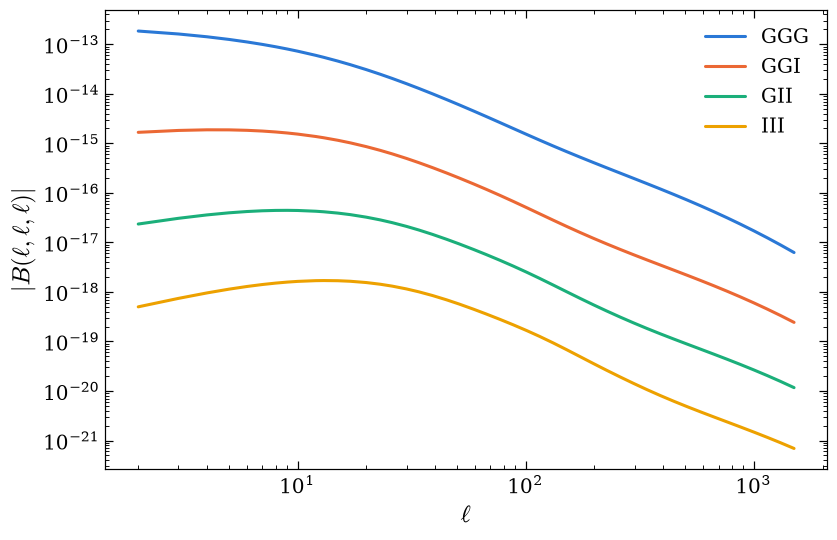

In [9]:
from bihalofit_jax import IA

L, I = 'lensing', 'ia'
terms = {name: make_projected_bihalofit(ell1, ell2, ell3, (n_z,) * 3, tr, pk_source='syren')
         for name, tr in {'GGG': (L, L, L), 'GGI': (L, L, I), 'GII': (L, I, I), 'III': (I, I, I)}.items()}

def B_obs(cosmo, ia):
    """GGG + 3 GGI + 3 GII + III; the GGG term takes no `ia`."""
    return (terms['GGG'](cosmo) + 3 * terms['GGI'](cosmo, ia=ia)
            + 3 * terms['GII'](cosmo, ia=ia) + terms['III'](cosmo, ia=ia))

ia = IA(A_IA=1.0, eta=0.0)
fig, ax = plt.subplots()
for name, f in terms.items():
    B = f(cosmo) if name == 'GGG' else f(cosmo, ia=ia)
    ax.loglog(ell1[eq], np.abs(B[0, eq]), label=name)
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$|B(\ell,\ell,\ell)|$'); ax.legend()
plt.show()

For $A_{\rm IA}>0$ the alignment kernel is negative, so GGI and III are negative and GII is positive; the
plot shows absolute values. Setting $\eta=0$ makes $B_{GGI}\propto A_{\rm IA}$, $B_{GII}\propto A_{\rm IA}^2$ and
$B_{III}\propto A_{\rm IA}^3$ exactly. Note that $1/D(z)$ already grows with redshift, so $\eta=0$ is not
"no redshift evolution".

The fractional effect on the total, and its derivatives with respect to the alignment parameters:

(1, 2411)


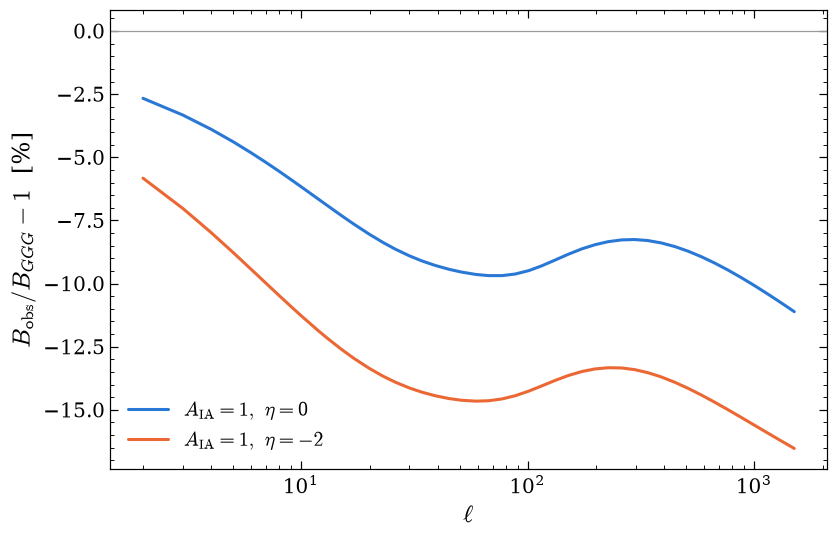

In [10]:
frac = lambda ia: B_obs(cosmo, ia)[0] / B_kappa[0] - 1

d = jax.jacfwd(B_obs, argnums=1)(cosmo, ia)                # an IA whose fields are derivatives
print(d.A_IA.shape)                                        # (N_cosmo, N_ltri, N_cosmo) = (1, 2411, 1)

fig, ax = plt.subplots()
ax.semilogx(ell1[eq], 100 * frac(IA(1.0, 0.0))[eq], label=r'$A_{\rm IA}=1,\ \eta=0$')
ax.semilogx(ell1[eq], 100 * frac(IA(1.0, -2.0))[eq], label=r'$A_{\rm IA}=1,\ \eta=-2$')
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$B_{\rm obs}/B_{GGG}-1$  [%]'); ax.legend()
plt.show()